# Experiment 6 — Random multi-UAV scalability

This experiment compares strategic-only and tactical-only deconfliction as the number of UAVs increases. For each strategy and each $N \in \{1, 2, 10, 50, 100\}$, ten independently seeded scenarios are simulated.

Every UAV receives a straight initial flight plan between two randomly selected points on different borders of the operating area. All plans use the same altitude and nominal time window. The same seed produces the same plans in both strategies, making the comparison paired and reproducible.

In [6]:
import csv
import fcntl
import math
import random
from pathlib import Path
from statistics import fmean

import matplotlib.pyplot as plt
from IPython.display import display

from musas.airspace import Airspace
from musas.algorithms import (
    DetourPathPlanner,
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    HybridGeometricManeuver,
    MinimumSeparationConflictPrediction,
    MinimumSeparationTacticalConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)

from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    calculate_metrics,
    plot_dataset,
)
from musas.domain import FlightPlan, Waypoint

OUTPUT_DIRECTORY = Path("outputs") / "output_exp6"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Experiment configuration

The seed of each replication is derived from $N$ and the replication index. Consequently, rerunning the notebook produces exactly the same scenarios.

In [ ]:
N_VALUES = (1, 2, 10, 50, 100)
K = 3
STRATEGIES = ("sd_only", "td_only", "sd_td")
STRATEGY_LABELS = {
    "sd_only": "SD only",
    "td_only": "TD only",
    "sd_td": "SD + TD",
}
BASE_SEED = 20261009

AREA_HALF_SIZE = 200.0
ALTITUDE = 100.0
DEPARTURE_TIME = 2.0
ARRIVAL_TIME = 62.0
SIMULATION_END = 100.0
MINIMUM_ROUTE_LENGTH = 150.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0
TIME_SHIFT_STEP = 3.0

METRIC_KEYS = (
    "detected_strategic_conflicts",
    "detected_tactical_conflicts",
    "detected_conflicts",
    "flights",
    "modified_flights",
    "rejected_flights",
    "tactical_interventions",
    "loss_of_separation_events",
    "collision_events",
    "minimum_pairwise_separation",
    "average_planned_distance",
    "average_actual_distance",
    "average_planned_time",
    "average_actual_time",
    "average_updates_per_uav",
)

## Random scenario generation

A point is sampled uniformly along one border. The destination is sampled from a different border, and very short routes are rejected. Each flight plan therefore contains exactly two waypoints and is initially rectilinear.

In [8]:
def point_on_border(rng, border):
    coordinate = rng.uniform(-AREA_HALF_SIZE, AREA_HALF_SIZE)
    if border == "left":
        return (-AREA_HALF_SIZE, coordinate)
    if border == "right":
        return (AREA_HALF_SIZE, coordinate)
    if border == "bottom":
        return (coordinate, -AREA_HALF_SIZE)
    return (coordinate, AREA_HALF_SIZE)


def random_flight_plan(rng):
    borders = ("left", "right", "bottom", "top")
    while True:
        start_border = rng.choice(borders)
        end_border = rng.choice([border for border in borders if border != start_border])
        start = point_on_border(rng, start_border)
        end = point_on_border(rng, end_border)
        if math.dist(start, end) >= MINIMUM_ROUTE_LENGTH:
            return FlightPlan([
                Waypoint(*start, ALTITUDE, DEPARTURE_TIME),
                Waypoint(*end, ALTITUDE, ARRIVAL_TIME),
            ])


def create_flight_plans(number_of_uavs, seed):
    rng = random.Random(seed)
    return {
        f"UAV {index + 1:03d}": random_flight_plan(rng)
        for index in range(number_of_uavs)
    }

## Run the simulations

In `SD only`, strategic prediction, path planning, and Recursive Time Shift FCFS operate before departure. In `TD only`, the dummy strategic layer approves every proposal and the tactical pipeline operates during flight. `SD + TD` combines both layers. Every simulation is stored in its own SQLite dataset.

In [9]:
def run_simulation(strategy, number_of_uavs, replication):
    seed = BASE_SEED + 1000 * number_of_uavs + replication
    dataset_path = (
        DATASET_DIRECTORY
        / f"{strategy}_n_{number_of_uavs:03d}_run_{replication + 1:02d}.sqlite"
    )

    if strategy not in STRATEGIES:
        raise ValueError(f"Unknown strategy: {strategy}")

    algorithm_arguments = {}
    if strategy in {"sd_only", "sd_td"}:
        conflict_prediction = MinimumSeparationConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            sampling_interval=1.0,
        )
        algorithm_arguments.update(
            strategic_conflict_prediction_algorithm=conflict_prediction,
            strategic_deconfliction_algorithm=RecursiveTimeShiftDeconfliction(
                conflict_prediction_algorithm=conflict_prediction,
                path_planner=DetourPathPlanner(
                    conflict_prediction_algorithm=conflict_prediction,
                ),
                time_shift_step=TIME_SHIFT_STEP,
                maximum_time_shifts=50,
            ),
        )
    if strategy in {"td_only", "sd_td"}:
        tactical_predictor = MinimumSeparationTacticalConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            maximum_time_difference=0.5,
        )
        algorithm_arguments.update(
            tracking_algorithm=FlightPlanAwareTracking(),
            tactical_conflict_prediction_algorithm=tactical_predictor,
            tactical_deconfliction_algorithm=HybridGeometricManeuver(
                conflict_prediction_algorithm=tactical_predictor,
                minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
                vertical_offset=60.0,
                maximum_speed=15.0,
                cooldown=20.0,
            ),
        )

    simulation = Simulation(
        airspace=Airspace(),
        report_interval=1.0,
        history_window=6,
        prediction_horizon=20,
        prediction_step=0.5,
        flight_update_interval=0.2,
        trajectory_record_interval=0.5,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "random_multi_uav_scalability",
            "strategy": strategy,
            "number_of_uavs": number_of_uavs,
            "replication": replication + 1,
            "seed": seed,
        },
        overwrite_dataset=True,
        keep_history_in_memory=False,
        **algorithm_arguments,
    )

    for index, (uav_name, flight_plan) in enumerate(
        create_flight_plans(number_of_uavs, seed).items()
    ):
        simulation.add_uav(
            name=uav_name,
            flight_plan=flight_plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=100.0,
                velocity_time_constant=0.0,
            ),
            guidance_algorithm=WaypointGuidance(
                min_speed=0.0,
                max_speed=15.0,
            ),
            submission_time=index * 0.01,
            waypoint_acceptance_radius=1.0,
        )

    simulation.run(until=SIMULATION_END)
    simulation.close()

    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
    metrics["average_updates_per_uav"] = fmean(
        values["updates"] for values in metrics["per_uav"].values()
    )
    metrics["detected_conflicts"] = (
        metrics["detected_strategic_conflicts"]
        + metrics["detected_tactical_conflicts"]
    )
    return {
        "strategy": strategy,
        "number_of_uavs": number_of_uavs,
        "replication": replication + 1,
        "seed": seed,
        **{key: metrics[key] for key in METRIC_KEYS},
    }

In [10]:
def execute_experiment():
    lock_path = OUTPUT_DIRECTORY / "experiment.lock"
    with lock_path.open("w") as lock_file:
        try:
            fcntl.flock(lock_file, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as error:
            raise RuntimeError(
                "Experiment 6 is already running in another process or kernel"
            ) from error

        results = []
        for strategy in STRATEGIES:
            for number_of_uavs in N_VALUES:
                for replication in range(K):
                    print(
                        f"{STRATEGY_LABELS[strategy]:7s} | N={number_of_uavs:3d} | "
                        f"replication={replication + 1:2d}/{K}",
                        end="\r",
                    )
                    results.append(
                        run_simulation(strategy, number_of_uavs, replication)
                    )
                print(
                    f"{STRATEGY_LABELS[strategy]:7s} | N={number_of_uavs:3d} | "
                    f"completed {K} replications"
                )
        return results


results = execute_experiment()

raw_results_path = OUTPUT_DIRECTORY / "replication_metrics.csv"
with raw_results_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print("Saved:", raw_results_path)

SD only | N=  1 | completed 10 replications
SD only | N=  2 | completed 10 replications
SD only | N= 10 | completed 10 replications
TD only | N=  1 | completed 10 replications
TD only | N=  2 | completed 10 replications
TD only | N= 10 | completed 10 replications
Saved: outputs/output_exp6/replication_metrics.csv


## Mean metrics

Each point below is the arithmetic mean of the $K$ replications for one strategy and value of $N$. `minimum_pairwise_separation` is undefined for $N=1$, because no UAV pair exists.

In [11]:
def mean_defined(values):
    defined = [value for value in values if value is not None]
    return fmean(defined) if defined else None


mean_metrics = []
for strategy in STRATEGIES:
    for number_of_uavs in N_VALUES:
        group = [
            row for row in results
            if row["strategy"] == strategy
            and row["number_of_uavs"] == number_of_uavs
        ]
        mean_metrics.append({
            "strategy": strategy,
            "number_of_uavs": number_of_uavs,
            **{
                key: mean_defined([row[key] for row in group])
                for key in METRIC_KEYS
            },
        })

summary_path = OUTPUT_DIRECTORY / "mean_metrics.csv"
with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=mean_metrics[0].keys())
    writer.writeheader()
    writer.writerows(mean_metrics)

header = (
    f"{'Strategy':<8} {'N':>4} {'conflicts':>10} {'modified':>10} {'rejected':>10} "
    f"{'LOS':>8} {'collisions':>11} {'min. sep.':>11} {'updates/UAV':>12}"
)
print(header)
for row in mean_metrics:
    minimum = row["minimum_pairwise_separation"]
    minimum_text = "n/a" if minimum is None else f"{minimum:.2f}"
    print(
        f"{STRATEGY_LABELS[row['strategy']]:<8} "
        f"{row['number_of_uavs']:4d} "
        f"{row['detected_conflicts']:10.2f} "
        f"{row['modified_flights']:10.2f} "
        f"{row['rejected_flights']:10.2f} "
        f"{row['loss_of_separation_events']:8.2f} "
        f"{row['collision_events']:11.2f} "
        f"{minimum_text:>11} "
        f"{row['average_updates_per_uav']:12.2f}"
    )
print("Saved:", summary_path)

Strategy    N  conflicts   modified   rejected      LOS  collisions   min. sep.  updates/UAV
SD only     1       0.00       0.00       0.00     0.00        0.00         n/a         0.00
SD only     2       0.20       0.20       0.00     0.00        0.00      106.35         0.10
SD only    10       8.40       5.80       0.00     0.00        0.00       31.76         0.58
TD only     1       0.00       0.00       0.00     0.00        0.00         n/a         0.00
TD only     2       0.50       0.20       0.00     0.00        0.00      105.64         0.10
TD only    10     102.80       5.90       0.00     7.10        1.10        3.20         0.92
Saved: outputs/output_exp6/mean_metrics.csv


## Comparative plots

The panels separate metrics with different units and scales. Counts are averages per simulation; distance and time metrics are averages per UAV within each simulation and then across replications.

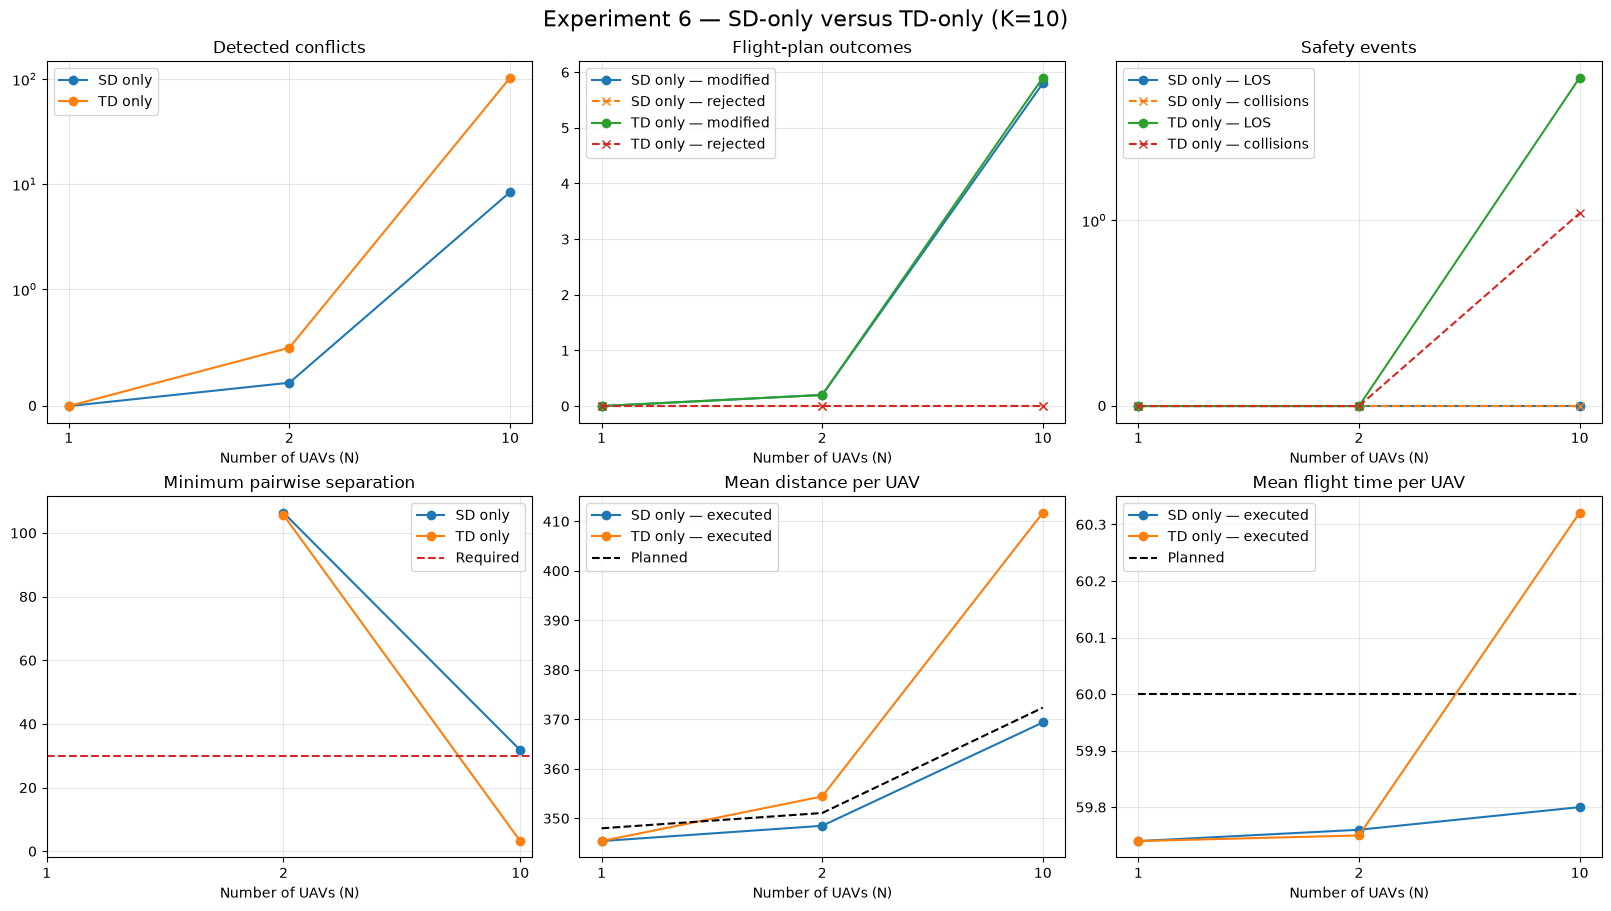

Saved: outputs/output_exp6/mean_metrics.png


In [12]:
def series(strategy, key):
    rows = [row for row in mean_metrics if row["strategy"] == strategy]
    return [
        float("nan") if row[key] is None else row[key]
        for row in rows
    ]


x_positions = range(len(N_VALUES))
figure, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)

for strategy in STRATEGIES:
    axes[0, 0].plot(
        x_positions, series(strategy, "detected_conflicts"),
        marker="o", label=STRATEGY_LABELS[strategy],
    )
axes[0, 0].set_title("Detected conflicts")
axes[0, 0].set_yscale("symlog", linthresh=1.0)
axes[0, 0].legend()

for strategy in STRATEGIES:
    axes[0, 1].plot(
        x_positions, series(strategy, "modified_flights"),
        marker="o", label=f"{STRATEGY_LABELS[strategy]} — modified",
    )
    axes[0, 1].plot(
        x_positions, series(strategy, "rejected_flights"),
        marker="x", linestyle="--",
        label=f"{STRATEGY_LABELS[strategy]} — rejected",
    )
axes[0, 1].set_title("Flight-plan outcomes")
axes[0, 1].legend()

for strategy in STRATEGIES:
    axes[0, 2].plot(
        x_positions, series(strategy, "loss_of_separation_events"),
        marker="o", label=f"{STRATEGY_LABELS[strategy]} — LOS",
    )
    axes[0, 2].plot(
        x_positions, series(strategy, "collision_events"),
        marker="x", linestyle="--",
        label=f"{STRATEGY_LABELS[strategy]} — collisions",
    )
axes[0, 2].set_title("Safety events")
axes[0, 2].set_yscale("symlog", linthresh=1.0)
axes[0, 2].legend()

for strategy in STRATEGIES:
    axes[1, 0].plot(
        x_positions, series(strategy, "minimum_pairwise_separation"),
        marker="o", label=STRATEGY_LABELS[strategy],
    )
axes[1, 0].axhline(MINIMUM_SEPARATION_DISTANCE, color="tab:red", linestyle="--", label="Required")
axes[1, 0].set_title("Minimum pairwise separation")
axes[1, 0].legend()

for strategy in STRATEGIES:
    axes[1, 1].plot(
        x_positions, series(strategy, "average_actual_distance"),
        marker="o", label=f"{STRATEGY_LABELS[strategy]} — executed",
    )
axes[1, 1].plot(
    x_positions, series("sd_only", "average_planned_distance"),
    color="black", linestyle="--", label="Planned",
)
axes[1, 1].set_title("Mean distance per UAV")
axes[1, 1].legend()

for strategy in STRATEGIES:
    axes[1, 2].plot(
        x_positions, series(strategy, "average_actual_time"),
        marker="o", label=f"{STRATEGY_LABELS[strategy]} — executed",
    )
axes[1, 2].plot(
    x_positions, series("sd_only", "average_planned_time"),
    color="black", linestyle="--", label="Planned",
)
axes[1, 2].set_title("Mean flight time per UAV")
axes[1, 2].legend()

for axis in axes.flat:
    axis.set_xlabel("Number of UAVs (N)")
    axis.grid(alpha=0.3)
    axis.set_xticks(x_positions, labels=N_VALUES)

figure.suptitle(f"Experiment 6 — SD, TD, and SD + TD (K={K})", fontsize=16)
figure_path = OUTPUT_DIRECTORY / "mean_metrics.png"
figure.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

In [13]:
def visualization_config():
    return VisualizationConfig(
        uav_names=None,
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=True,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        show_legend=False,
        frame_step=0.5,
        figure_size=(10.0, 8.0),
    )


dataset_path = (
    OUTPUT_DIRECTORY
    / "datasets"
    / "td_only_n_100_run_10.sqlite"
)
figure_path = OUTPUT_DIRECTORY / "td_only_n_100_run_10_t50.png"

figure = plot_dataset(
    dataset_path=dataset_path,
    config=visualization_config(),
    timestamp=50.0,
    output_path=figure_path,
)

display(figure)
print("Saved:", figure_path)

FileNotFoundError: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/experiments/outputs/output_exp6/datasets/td_only_n_100_run_10.sqlite